In [ ]:
!pip install imbalanced-learn

In [ ]:
# ===========================
# IMPORT LIBRARY
# ===========================

import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

# Split Dataset
from sklearn.model_selection import train_test_split

# Algoritma
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Oversampling
from imblearn.over_sampling import SMOTE

# Evaluasi
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd

# ==========================================
# LOAD DATASET
# ==========================================

df = pd.read_csv('/content/healthcare-dataset-stroke-data.csv', sep=';')

df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# Jumlah baris dan kolom

print("Jumlah Baris dan Kolom :")
print(df.shape)

Jumlah Baris dan Kolom :
(5110, 12)


In [ ]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.tail()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.00,17741.250,36932.000,54682.00,72940.00
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,28.893237,7.854067,10.30,23.500,28.100,33.10,97.60
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


In [ ]:
df.dtypes

,0
id,int64
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64


In [ ]:
print(df.isnull().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


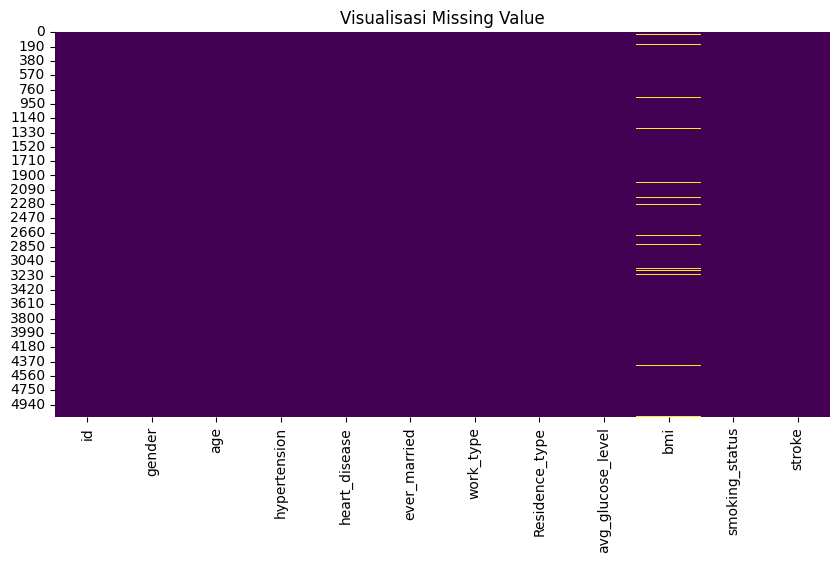

In [ ]:
plt.figure(figsize=(10,5))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap='viridis')

plt.title("Visualisasi Missing Value")

plt.show()

In [ ]:
print("Jumlah Data Duplikat :")

print(df.duplicated().sum())

Jumlah Data Duplikat :
0


In [ ]:
print(df['stroke'].value_counts())

stroke
0    4861
1     249
Name: count, dtype: int64


In [ ]:
print(df['stroke'].value_counts(normalize=True)*100)

stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


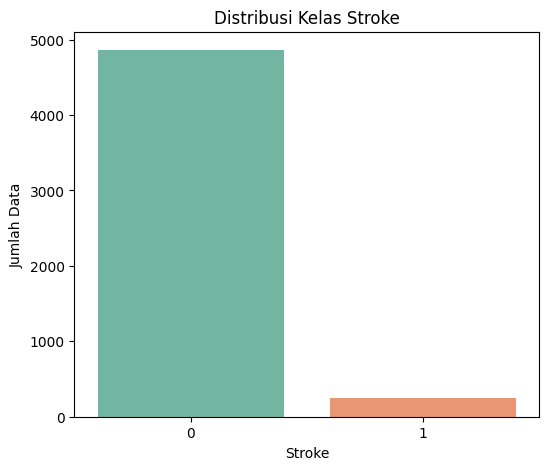

In [ ]:
plt.figure(figsize=(6,5))

sns.countplot(
    x='stroke',
    data=df,
    palette='Set2'
)

plt.title("Distribusi Kelas Stroke")

plt.xlabel("Stroke")

plt.ylabel("Jumlah Data")

plt.show()

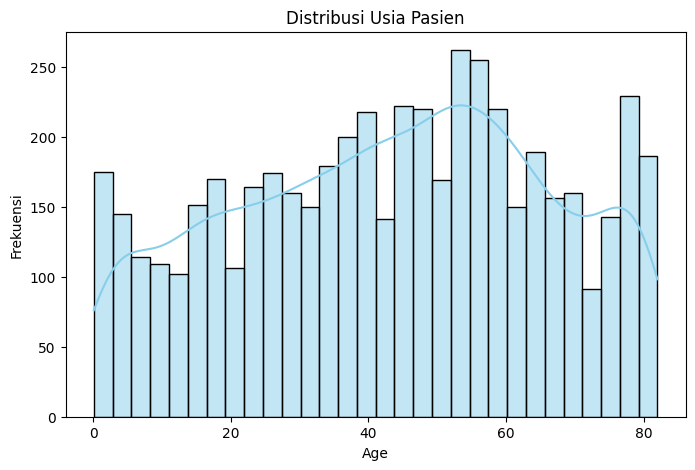

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['age'],
    bins=30,
    kde=True,
    color='skyblue'
)

plt.title("Distribusi Usia Pasien")

plt.xlabel("Age")

plt.ylabel("Frekuensi")

plt.show()

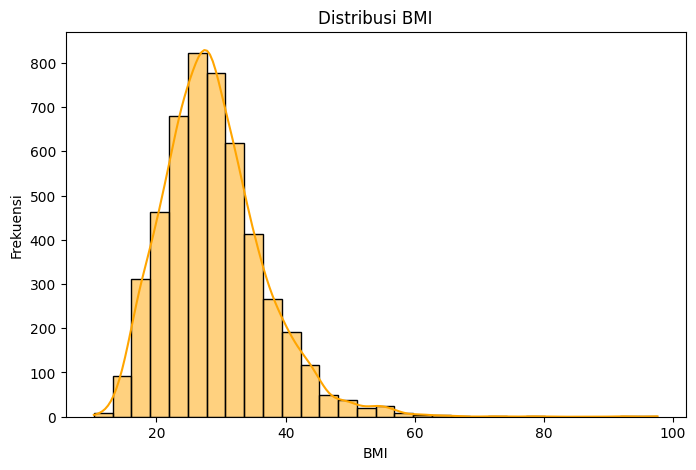

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['bmi'],
    bins=30,
    kde=True,
    color='orange'
)

plt.title("Distribusi BMI")

plt.xlabel("BMI")

plt.ylabel("Frekuensi")

plt.show()

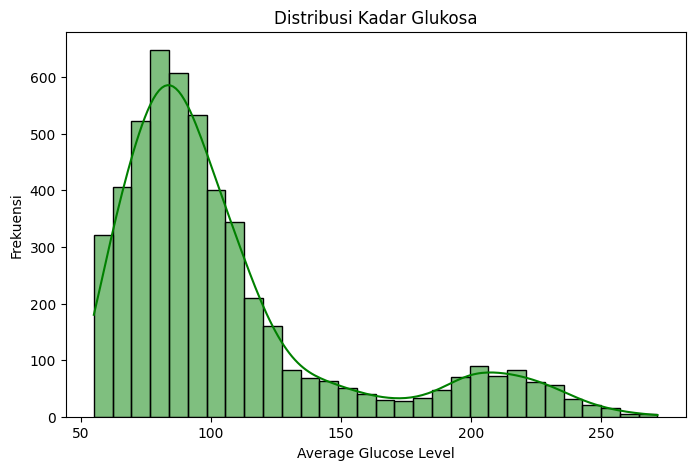

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['avg_glucose_level'],
    bins=30,
    kde=True,
    color='green'
)

plt.title("Distribusi Kadar Glukosa")

plt.xlabel("Average Glucose Level")

plt.ylabel("Frekuensi")

plt.show()

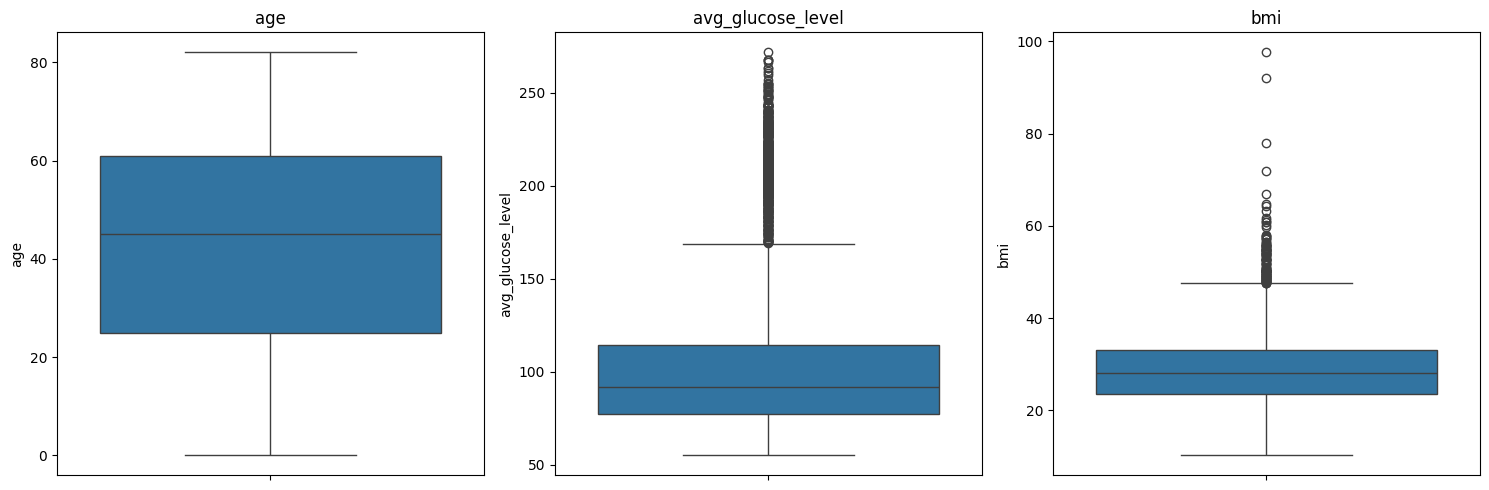

In [ ]:
numerical = [
    'age',
    'avg_glucose_level',
    'bmi'
]

plt.figure(figsize=(15,5))

for i,col in enumerate(numerical):

    plt.subplot(1,3,i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()

plt.show()

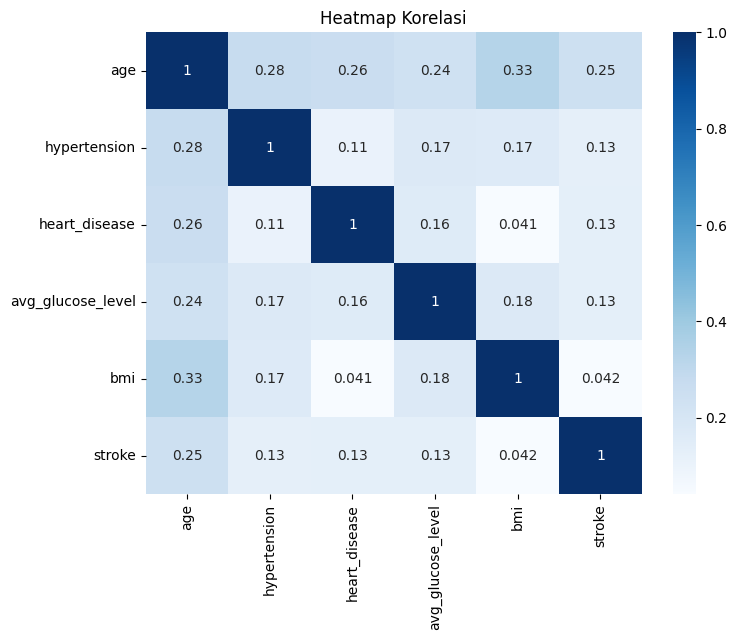

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[['age',
        'hypertension',
        'heart_disease',
        'avg_glucose_level',
        'bmi',
        'stroke']].corr(),
    annot=True,
    cmap='Blues'
)

plt.title("Heatmap Korelasi")

plt.show()

In [ ]:
categorical = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]
for col in categorical:
    print("="*40)
    print(col)
    print(df[col].value_counts())
    print()

gender
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

ever_married
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

work_type
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Residence_type
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

smoking_status
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64



In [ ]:
# ==========================================
# MENGHAPUS KOLOM ID
# ==========================================

df = df.drop(columns=['id'])

df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# ==========================================
# CEK MISSING VALUE
# ==========================================

df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201
smoking_status,0


In [ ]:
# ==========================================
# MENGISI NILAI BMI YANG KOSONG
# ==========================================

median_bmi = df['bmi'].median()

df['bmi'] = df['bmi'].fillna(median_bmi)

In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# ==========================================
# LABEL ENCODING
# ==========================================
categorical_columns = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]
label_encoder = LabelEncoder()
for col in categorical_columns:

    df[col] = label_encoder.fit_transform(df[col])

In [ ]:
df.head()

NameError: name 'df' is not defined

In [ ]:
df.dtypes

,0
gender,int64
age,float64
hypertension,int64
heart_disease,int64
ever_married,int64
work_type,int64
Residence_type,int64
avg_glucose_level,float64
bmi,float64
smoking_status,int64


In [ ]:
# ==========================================
# MEMISAHKAN FITUR DAN TARGET
# ==========================================

X = df.drop('stroke', axis=1)

y = df['stroke']

In [ ]:
print("Jumlah Feature :", X.shape)

print("Jumlah Target :", y.shape)

Jumlah Feature : (5110, 10)
Jumlah Target : (5110,)


In [ ]:
# ==========================================
# FEATURE SCALING
# ==========================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
X_scaled

array([[ 1.18807255,  1.05143428, -0.32860186, ...,  2.70637544,
         1.00508597, -0.35178071],
       [-0.840344  ,  0.78607007, -0.32860186, ...,  2.12155854,
        -0.09898092,  0.58155233],
       [ 1.18807255,  1.62639008, -0.32860186, ..., -0.0050283 ,
         0.47253605,  0.58155233],
       ...,
       [-0.840344  , -0.36384151, -0.32860186, ..., -0.51144264,
         0.22574463,  0.58155233],
       [ 1.18807255,  0.34379639, -0.32860186, ...,  1.32825706,
        -0.42370648, -0.35178071],
       [-0.840344  ,  0.03420481, -0.32860186, ..., -0.46086746,
        -0.34577235, -1.28511375]])

In [ ]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardisasi
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [ ]:
# ==========================================
# SMOTE
# ==========================================

smote = SMOTE(
    random_state=42
)

X_train, y_train = smote.fit_resample(
    X_train,
    y_train
)

In [ ]:
print("Data Training :", X_train.shape)
print("Data Testing :", X_test.shape)
print("Target Training :", y_train.shape)
print("Target Testing :", y_test.shape)

Data Training : (7778, 10)
Data Testing : (1022, 10)
Target Training : (7778,)
Target Testing : (1022,)


In [ ]:
print("Training")
print(y_train.value_counts())
print()
print("Testing")
print(y_test.value_counts())

Training
stroke
0    3889
1    3889
Name: count, dtype: int64

Testing
stroke
0    972
1     50
Name: count, dtype: int64


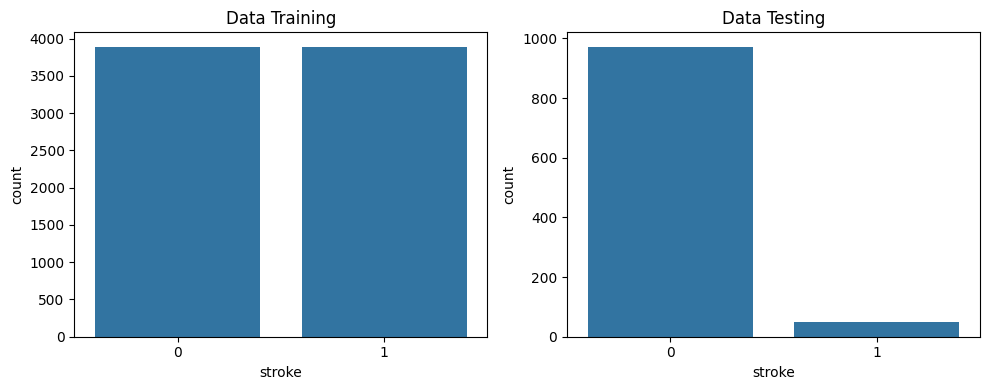

In [ ]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.countplot(x=y_train)
plt.title("Data Training")
plt.subplot(1,2,2)
sns.countplot(x=y_test)
plt.title("Data Testing")
plt.tight_layout()
plt.show()

In [ ]:
print("="*50)
print("PRA-PEMROSESAN SELESAI")
print("="*50)
print("Jumlah Data :", len(df))
print("Jumlah Feature :", X.shape[1])
print("Jumlah Target :", len(y))
print("Missing Value :", df.isnull().sum().sum())
print("Duplikat :", df.duplicated().sum())

PRA-PEMROSESAN SELESAI
Jumlah Data : 5110
Jumlah Feature : 10
Jumlah Target : 5110
Missing Value : 0
Duplikat : 0


In [ ]:
# ==========================================
# MEMBANGUN MODEL SVM
# ==========================================

svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

In [ ]:
# ==========================================
# TRAINING MODEL SVM
# ==========================================
svm_model.fit(X_train, y_train)
print("Model SVM berhasil dilatih.")

Model SVM berhasil dilatih.


In [ ]:
# ==========================================
# PREDIKSI DATA TESTING
# ==========================================
y_pred_svm = svm_model.predict(X_test)

In [ ]:
# ==========================================
# PROBABILITAS PREDIKSI
# ==========================================
y_prob_svm = svm_model.predict_proba(X_test)[:,1]

In [ ]:
# ==========================================
# ACCURACY
# ==========================================
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print("Accuracy SVM :", round(accuracy_svm,4))

Accuracy SVM : 0.7671


In [ ]:
# ==========================================
# PRECISION
# ==========================================
precision_svm = precision_score(y_test, y_pred_svm)
print("Precision SVM :", round(precision_svm,4))

Precision SVM : 0.1179


In [ ]:
# ==========================================
# RECALL
# ==========================================
recall_svm = recall_score(y_test, y_pred_svm)
print("Recall SVM :", round(recall_svm,4))

Recall SVM : 0.58


In [ ]:
# ==========================================
# F1 SCORE
# ==========================================
f1_svm = f1_score(y_test, y_pred_svm)
print("F1 Score SVM :", round(f1_svm,4))

F1 Score SVM : 0.1959


In [ ]:
# ==========================================
# ROC AUC
# ==========================================
roc_auc_svm = roc_auc_score(y_test, y_prob_svm)
print("ROC AUC SVM :", round(roc_auc_svm,4))

ROC AUC SVM : 0.7762


In [ ]:
# ==========================================
# CLASSIFICATION REPORT
# ==========================================

print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.97      0.78      0.86       972
           1       0.12      0.58      0.20        50

    accuracy                           0.77      1022
   macro avg       0.55      0.68      0.53      1022
weighted avg       0.93      0.77      0.83      1022



In [ ]:
# ==========================================
# CONFUSION MATRIX
# ==========================================

cm_svm = confusion_matrix(y_test, y_pred_svm)

cm_svm

array([[755, 217],
       [ 21,  29]])

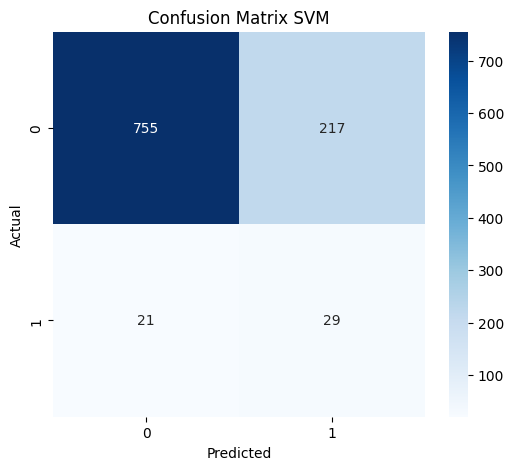

In [ ]:
# ==========================================
# HEATMAP CONFUSION MATRIX
# ==========================================
plt.figure(figsize=(6,5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title("Confusion Matrix SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

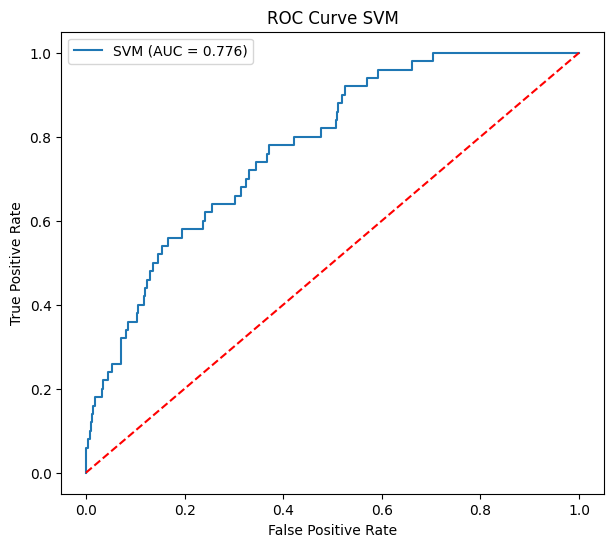

In [ ]:
# ==========================================
# ROC CURVE
# ==========================================
fpr, tpr, threshold = roc_curve(y_test, y_prob_svm)
roc_score = auc(fpr, tpr)
plt.figure(figsize=(7,6))
plt.plot(
    fpr,
    tpr,
    label='SVM (AUC = %0.3f)' % roc_score
)
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve SVM")
plt.legend()
plt.show()

In [ ]:
# ==========================================
# HASIL EVALUASI SVM
# ==========================================
hasil_svm = pd.DataFrame({
    'Metrik' : [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC AUC'
    ],
    'Nilai' : [
        accuracy_svm,
        precision_svm,
        recall_svm,
        f1_svm,
        roc_auc_svm
    ]
})
hasil_svm

,Metrik,Nilai
0,Accuracy,0.767123
1,Precision,0.117886
2,Recall,0.580000
3,F1 Score,0.195946
4,ROC AUC,0.776235


In [ ]:
print("="*50)

print("HASIL MODEL SUPPORT VECTOR MACHINE")
print("="*50)
print("Accuracy  :", round(accuracy_svm,4))
print("Precision :", round(precision_svm,4))
print("Recall    :", round(recall_svm,4))
print("F1 Score  :", round(f1_svm,4))
print("ROC AUC   :", round(roc_auc_svm,4))

HASIL MODEL SUPPORT VECTOR MACHINE
Accuracy  : 0.7671
Precision : 0.1179
Recall    : 0.58
F1 Score  : 0.1959
ROC AUC   : 0.7762


In [ ]:
# ==========================================
# MEMBANGUN MODEL XGBOOST
# ==========================================
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    eval_metric='logloss'

)

In [ ]:
# ==========================================
# TRAINING MODEL XGBOOST
# ==========================================
xgb_model.fit(
    X_train,
    y_train
)
print("Model XGBoost berhasil dilatih.")

Model XGBoost berhasil dilatih.


In [ ]:
# ==========================================
# PREDIKSI DATA TESTING
# ==========================================

y_pred_xgb = xgb_model.predict(X_test)

In [ ]:
# ==========================================
# PROBABILITAS PREDIKSI
# ==========================================

y_prob_xgb = xgb_model.predict_proba(X_test)[:,1]

In [ ]:
# ==========================================
# ACCURACY
# ==========================================
accuracy_xgb = accuracy_score(
    y_test,
    y_pred_xgb
)
print("Accuracy XGBoost :", round(accuracy_xgb,4))

Accuracy XGBoost : 0.9256


In [ ]:
# ==========================================
# PRECISION
# ==========================================
precision_xgb = precision_score(
    y_test,
    y_pred_xgb
)
print("Precision XGBoost :", round(precision_xgb,4))

Precision XGBoost : 0.2292


In [ ]:
# ==========================================
# RECALL
# ==========================================
recall_xgb = recall_score(
    y_test,
    y_pred_xgb
)
print("Recall XGBoost :", round(recall_xgb,4))

Recall XGBoost : 0.22


In [ ]:
# ==========================================
# F1 SCORE
# ==========================================
f1_xgb = f1_score(
    y_test,
    y_pred_xgb
)
print("F1 Score XGBoost :", round(f1_xgb,4))

F1 Score XGBoost : 0.2245


In [ ]:
# ==========================================
# ROC AUC
# ==========================================
roc_auc_xgb = roc_auc_score(
    y_test,
    y_prob_xgb
)
print("ROC AUC :", round(roc_auc_xgb,4))

ROC AUC : 0.8017


In [ ]:
# ==========================================
# CLASSIFICATION REPORT
# ==========================================
print(classification_report(
    y_test,
    y_pred_xgb
))

              precision    recall  f1-score   support

           0       0.96      0.96      0.96       972
           1       0.23      0.22      0.22        50

    accuracy                           0.93      1022
   macro avg       0.59      0.59      0.59      1022
weighted avg       0.92      0.93      0.92      1022



In [ ]:
# ==========================================
# CONFUSION MATRIX
# ==========================================
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)
cm_xgb

array([[935,  37],
       [ 39,  11]])

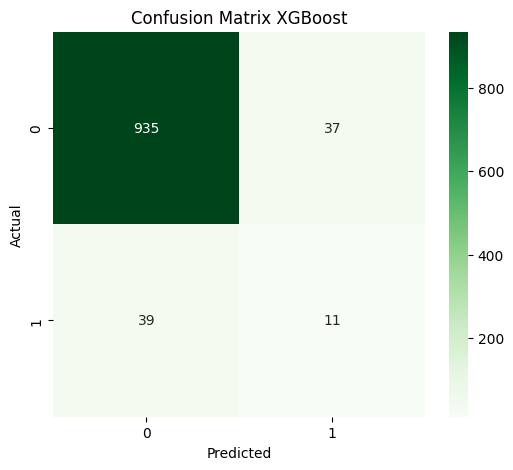

In [ ]:
# ==========================================
# VISUALISASI CONFUSION MATRIX
# ==========================================
plt.figure(figsize=(6,5))
sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Greens'
)
plt.title("Confusion Matrix XGBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

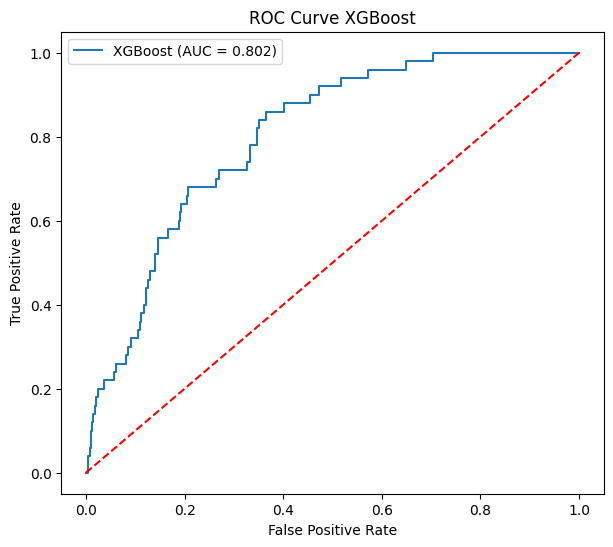

In [ ]:
# ==========================================
# ROC CURVE
# ==========================================
fpr_xgb, tpr_xgb, threshold_xgb = roc_curve(
    y_test,
    y_prob_xgb
)
roc_score_xgb = auc(
    fpr_xgb,
    tpr_xgb
)
plt.figure(figsize=(7,6))
plt.plot(
    fpr_xgb,
    tpr_xgb,
    label='XGBoost (AUC = %0.3f)' % roc_score_xgb
)
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve XGBoost")
plt.legend()
plt.show()

In [ ]:
# ==========================================
# FEATURE IMPORTANCE
# ==========================================
importance = pd.DataFrame({
    'Feature' : X.columns,
    'Importance' : xgb_model.feature_importances_
})
importance = importance.sort_values(
    by='Importance',
    ascending=False
)
importance

,Feature,Importance
1,age,0.245430
9,smoking_status,0.194383
5,work_type,0.146292
6,Residence_type,0.080286
0,gender,0.074951
4,ever_married,0.070813
3,heart_disease,0.055176
8,bmi,0.049487
2,hypertension,0.046525
7,avg_glucose_level,0.036656


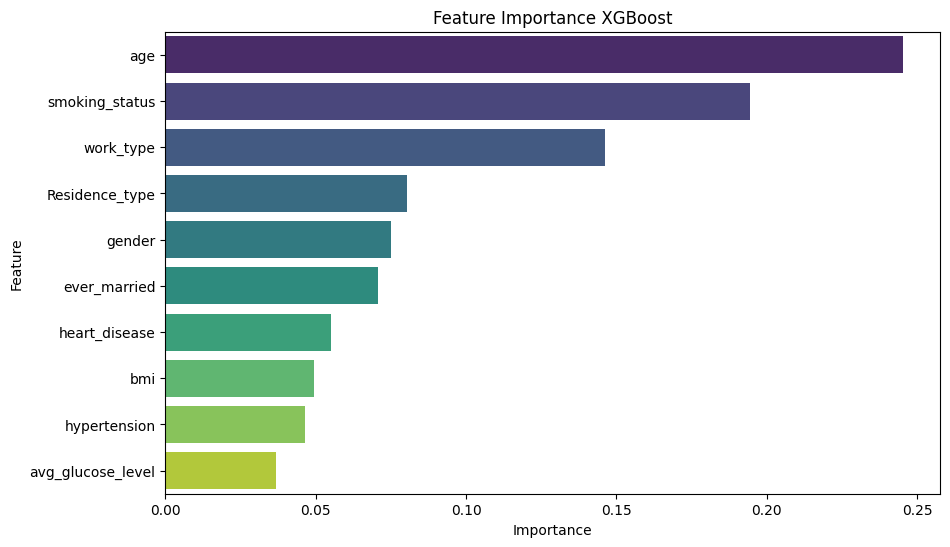

In [ ]:
# ==========================================
# GRAFIK FEATURE IMPORTANCE
# ==========================================
plt.figure(figsize=(10,6))
sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title("Feature Importance XGBoost")
plt.show()

In [ ]:
# ==========================================
# HASIL EVALUASI XGBOOST
# ==========================================
hasil_xgb = pd.DataFrame({
    'Metrik' : [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC AUC'
    ],
    'Nilai' : [
        accuracy_xgb,
        precision_xgb,
        recall_xgb,
        f1_xgb,
        roc_auc_xgb
    ]
})
hasil_xgb

,Metrik,Nilai
0,Accuracy,0.925636
1,Precision,0.229167
2,Recall,0.220000
3,F1 Score,0.224490
4,ROC AUC,0.801667


In [ ]:
print("="*50)
print("HASIL MODEL XGBOOST")
print("="*50)
print("Accuracy  :", round(accuracy_xgb,4))
print("Precision :", round(precision_xgb,4))
print("Recall    :", round(recall_xgb,4))
print("F1 Score  :", round(f1_xgb,4))
print("ROC AUC   :", round(roc_auc_xgb,4))

HASIL MODEL XGBOOST
Accuracy  : 0.9256
Precision : 0.2292
Recall    : 0.22
F1 Score  : 0.2245
ROC AUC   : 0.8017


In [ ]:
# ==========================================
# PERBANDINGAN HASIL MODEL
# ==========================================
hasil_perbandingan = pd.DataFrame({
    'Algoritma' : [
        'Support Vector Machine',
        'XGBoost'
    ],
    'Accuracy' : [
        accuracy_svm,
        accuracy_xgb
    ],
    'Precision' : [
        precision_svm,
        precision_xgb
    ],
    'Recall' : [
        recall_svm,
        recall_xgb
    ],
    'F1 Score' : [
        f1_svm,
        f1_xgb
    ],
    'ROC AUC' : [
        roc_auc_svm,
        roc_auc_xgb
    ]
})
hasil_perbandingan

,Algoritma,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Support Vector Machine,0.767123,0.117886,0.58,0.195946,0.776235
1,XGBoost,0.925636,0.229167,0.22,0.224490,0.801667


In [ ]:
hasil_perbandingan = hasil_perbandingan.round(4)
hasil_perbandingan

,Algoritma,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Support Vector Machine,0.7671,0.1179,0.58,0.1959,0.7762
1,XGBoost,0.9256,0.2292,0.22,0.2245,0.8017


In [ ]:
# ==========================================
# MODEL TERBAIK
# ==========================================
terbaik = hasil_perbandingan.sort_values(
    by='ROC AUC',
    ascending=False
)
terbaik

,Algoritma,Accuracy,Precision,Recall,F1 Score,ROC AUC
1,XGBoost,0.9256,0.2292,0.22,0.2245,0.8017
0,Support Vector Machine,0.7671,0.1179,0.58,0.1959,0.7762


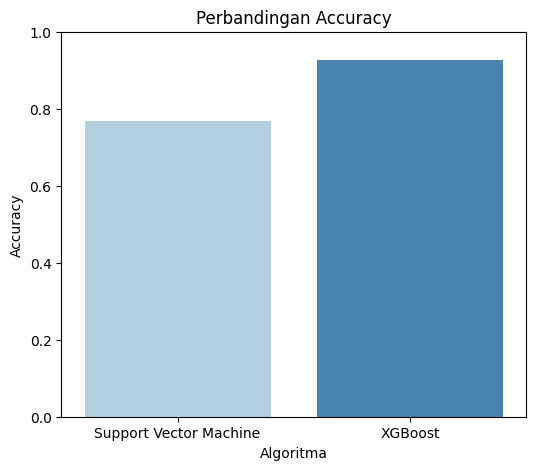

In [ ]:
plt.figure(figsize=(6,5))
sns.barplot(
    data=hasil_perbandingan,
    x='Algoritma',
    y='Accuracy',
    palette='Blues'
)
plt.ylim(0,1)
plt.title("Perbandingan Accuracy")
plt.show()

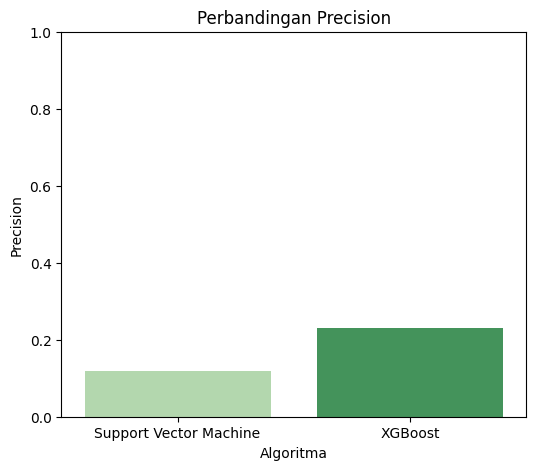

In [ ]:
plt.figure(figsize=(6,5))
sns.barplot(
    data=hasil_perbandingan,
    x='Algoritma',
    y='Precision',
    palette='Greens'
)
plt.ylim(0,1)
plt.title("Perbandingan Precision")
plt.show()

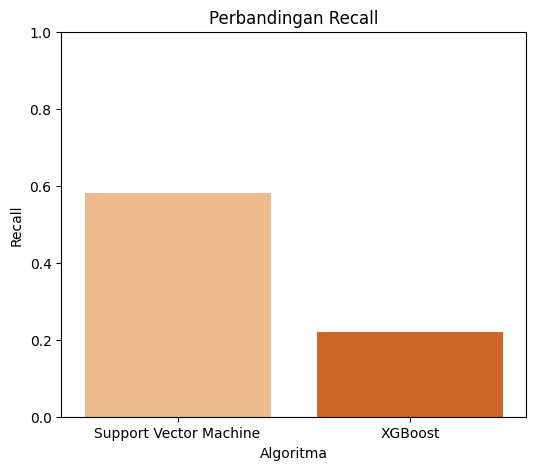

In [ ]:
plt.figure(figsize=(6,5))
sns.barplot(
    data=hasil_perbandingan,
    x='Algoritma',
    y='Recall',
    palette='Oranges'
)
plt.ylim(0,1)
plt.title("Perbandingan Recall")
plt.show()

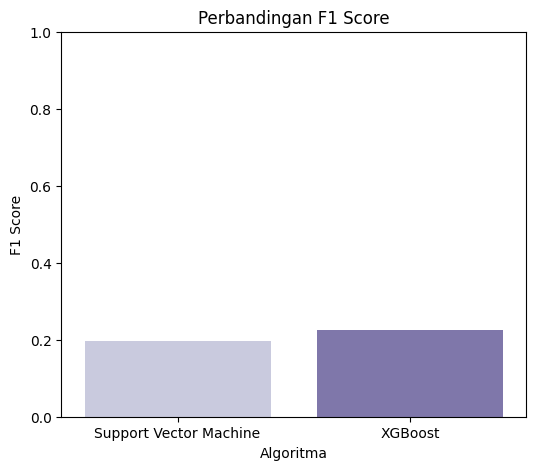

In [ ]:
plt.figure(figsize=(6,5))
sns.barplot(
    data=hasil_perbandingan,
    x='Algoritma',
    y='F1 Score',
    palette='Purples'
)
plt.ylim(0,1)
plt.title("Perbandingan F1 Score")
plt.show()

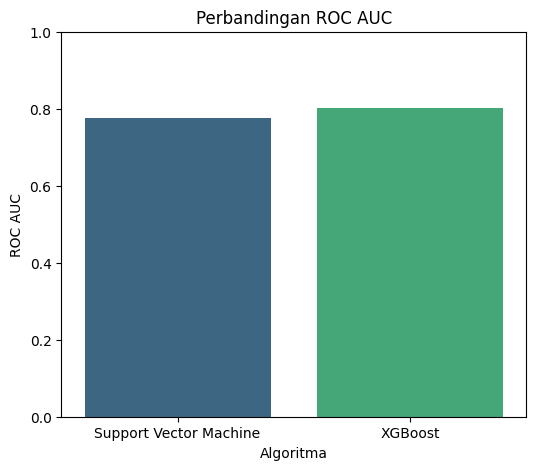

In [ ]:
plt.figure(figsize=(6,5))
sns.barplot(
    data=hasil_perbandingan,
    x='Algoritma',
    y='ROC AUC',
    palette='viridis'
)
plt.ylim(0,1)
plt.title("Perbandingan ROC AUC")
plt.show()

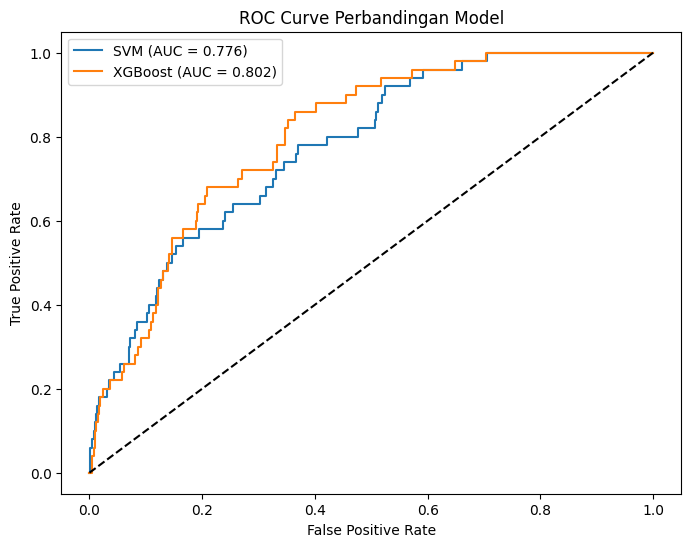

In [ ]:
plt.figure(figsize=(8,6))
plt.plot(
    fpr,
    tpr,
    label="SVM (AUC = %.3f)" % roc_auc_svm
)
plt.plot(
    fpr_xgb,
    tpr_xgb,
    label="XGBoost (AUC = %.3f)" % roc_auc_xgb
)
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Perbandingan Model")
plt.legend()
plt.show()

In [ ]:
print("="*60)
print("MODEL TERBAIK")
print("="*60)
print(
hasil_perbandingan.sort_values(
by='ROC AUC',
ascending=False
)
)

MODEL TERBAIK
                Algoritma  Accuracy  Precision  Recall  F1 Score  ROC AUC
1                 XGBoost    0.9256     0.2292    0.22    0.2245   0.8017
0  Support Vector Machine    0.7671     0.1179    0.58    0.1959   0.7762


In [ ]:
pasien_baru = np.array([
    [
        1,
        67,
        1,
        1,
        1,
        2,
        1,
        228.69,
        36.6,
        1
    ]
])

In [ ]:
pasien_baru = scaler.transform(
    pasien_baru
)

In [ ]:
prediksi_svm = svm_model.predict(
    pasien_baru
)
print(prediksi_svm)

[1]


In [ ]:
prediksi_xgb = xgb_model.predict(
    pasien_baru
)
print(prediksi_xgb)

[1]


In [ ]:
if prediksi_svm[0] == 1:
    print("SVM : Pasien Berisiko Stroke")
else:
    print("SVM : Pasien Tidak Berisiko Stroke")
if prediksi_xgb[0] == 1:
    print("XGBoost : Pasien Berisiko Stroke")
else:
    print("XGBoost : Pasien Tidak Berisiko Stroke")

SVM : Pasien Berisiko Stroke
XGBoost : Pasien Berisiko Stroke


In [ ]:
hasil_perbandingan.to_csv(
    "Hasil_Perbandingan_Model.csv",
    index=False
)
print("File berhasil disimpan.")

File berhasil disimpan.


In [ ]:
model_terbaik = hasil_perbandingan.loc[
    hasil_perbandingan['ROC AUC'].idxmax(), 'Algoritma'
]
print("="*60)
print("KESIMPULAN")
print("="*60)
print(f"Model dengan performa terbaik adalah: {model_terbaik}")

KESIMPULAN
Model dengan performa terbaik adalah: XGBoost
